In [2]:
cd examples/mitbih_tf_rmia

/volatile/home/yb285618/SSF/declearn/examples/mitbih_tf_rmia


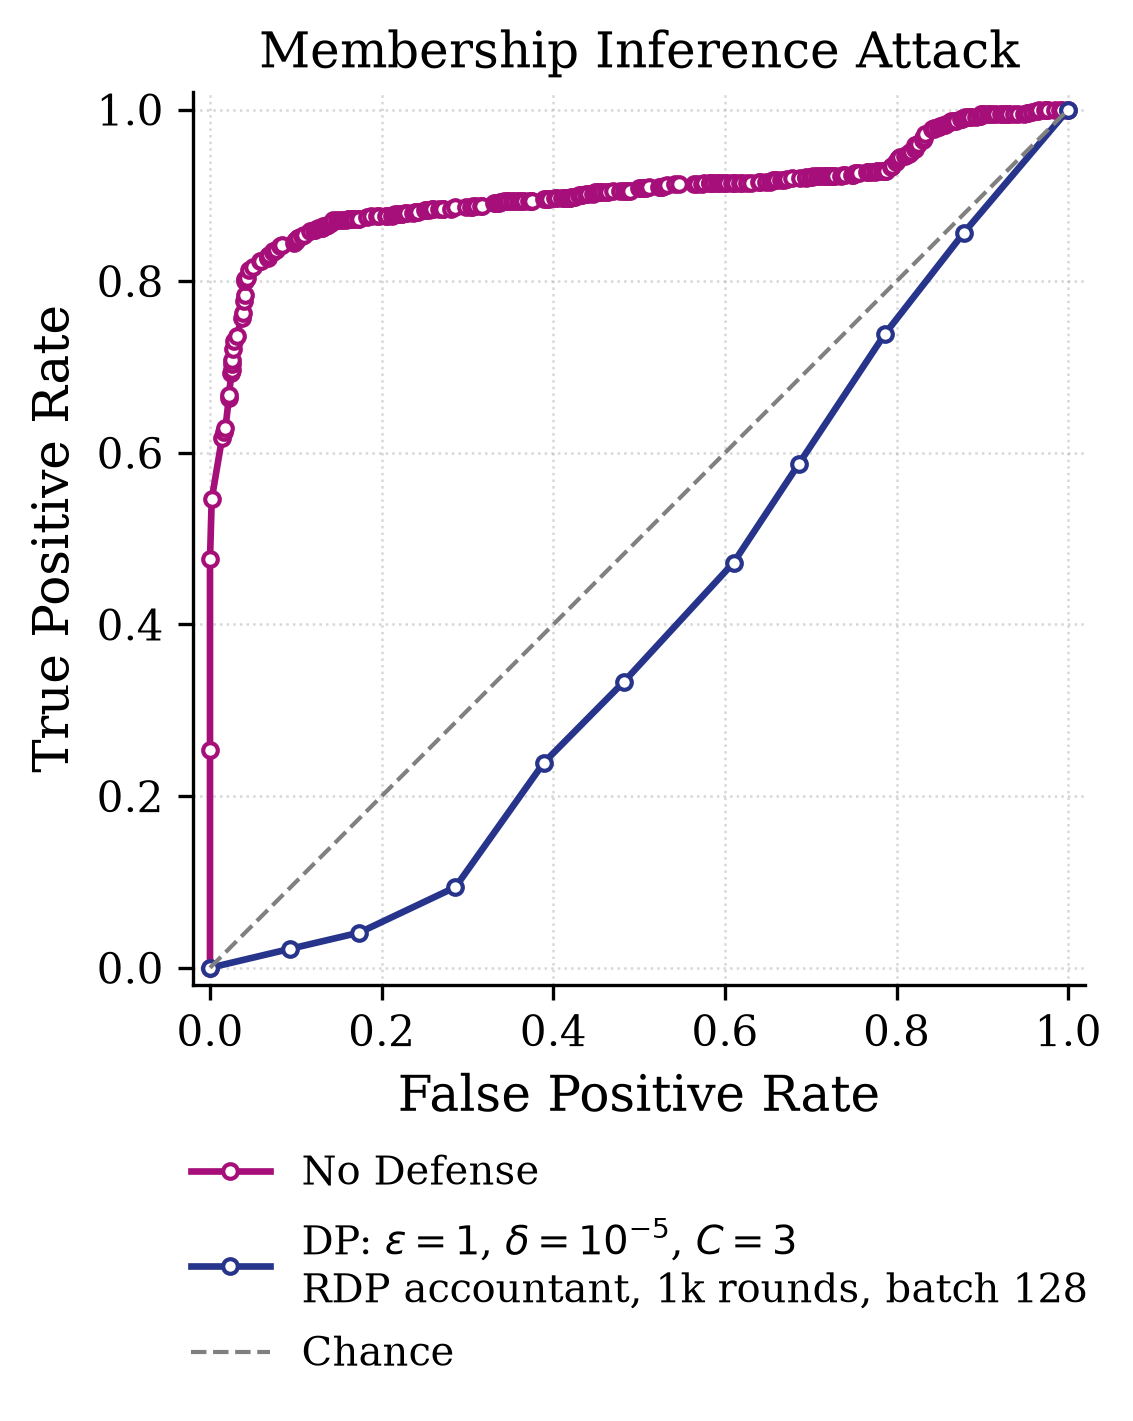

In [3]:
import json
import re

import matplotlib.pyplot as plt

# ---- Config: one entry per experiment to compare ----
EXPERIMENTS = [
    {
        "label": "No Defense",  # "NO DP",
        "json_path": "result_26-09-11_12-02/server/adversarial_metrics.json",
        "color": "#A60F79",
    },
    {
        "label": r"DP: $\varepsilon=1$, $\delta=10^{-5}$, $C=3$"
        "\n"
        r"RDP accountant, 1k rounds, batch 128",
        "json_path": "result_26-10-06_19-47/server/adversarial_metrics.json",
        "color": "#27348B",
    },
]


def load_worst_round(json_path):
    """Load the round with the highest AUC ('worst' for privacy) from a
    declearn adversarial_metrics.json file."""
    with open(json_path) as f:
        data = json.load(f)

    worst_key = max(data, key=lambda k: data[k]["auc"])
    round_num = re.search(r"(\d+)$", worst_key).group(1)
    round_data = data[worst_key]

    # Metric keys can vary between runs (e.g. "tpr@0.002", "TPR@0.001", ...).
    # Grab whichever low-FPR TPR key is present rather than hardcoding one.
    low_tpr_key = next(
        (k for k in round_data if k.lower().startswith("tpr@")), None
    )

    return {
        "round": round_num,
        "fpr": round_data["fpr"],
        "tpr": round_data["tpr"],
        "auc": round_data["auc"],
        "low_tpr_key": low_tpr_key,
        "low_tpr_value": round_data[low_tpr_key] if low_tpr_key else None,
    }


# ---- Paper-quality styling ----
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.size": 11,
        "axes.labelsize": 12,
        "axes.titlesize": 12,
        "legend.fontsize": 9.5,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "axes.linewidth": 0.8,
        "figure.dpi": 300,
        "savefig.dpi": 300,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)

fig, ax = plt.subplots(figsize=(5, 5))

for exp in EXPERIMENTS:
    res = load_worst_round(exp["json_path"])
    label = exp["label"]
    # label = f"{exp['label']} — round {res['round']} (AUC={res['auc']:.3f}"
    # if res["low_tpr_key"] is not None:
    #     label += f", {res['low_tpr_key'].upper()}={res['low_tpr_value']:.3f}"
    # label += ")"

    ax.plot(
        res["fpr"],
        res["tpr"],
        marker="o",
        markersize=3.5,
        markerfacecolor="white",
        markeredgewidth=1.0,
        linewidth=1.6,
        color=exp["color"],
        label=label,
    )

ax.plot(
    [0, 1], [0, 1], linestyle="--", color="gray", linewidth=1.0, label="Chance"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title(
    "Membership Inference Attack"  # "RMIA — worst-case round per run\n"
    # "(n_target_samples = 1000, n_pop_samples = 500, num_ref_models = 10)"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(True, linestyle=":", linewidth=0.6, alpha=0.5)

ax.legend(
    loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False, ncol=1
)
ax.set_aspect("equal")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)

fig.tight_layout()
fig.savefig("roc_comparison.pdf", bbox_inches="tight")
plt.show()

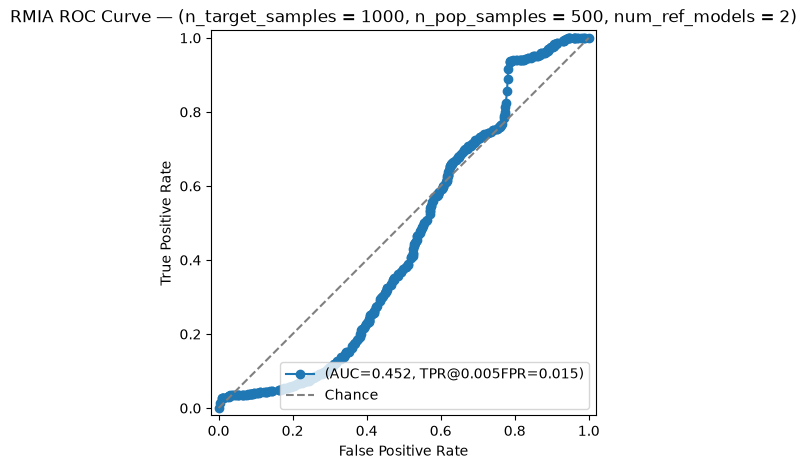

In [20]:
import json
import re
import matplotlib.pyplot as plt
import pandas as pd

json_path = "result_26-09-11_13-02/server/adversarial_metrics.json"
csv_path = "result_26-09-11_13-02/server/adversarial_metrics.csv"


with open(json_path) as f:
    data = json.load(f)

# pick round with lowest AUC ("worst")
worst_key = max(data, key=lambda k: data[k]["auc"])
round_num = re.search(r"(\d+)$", worst_key).group(1)

fpr = data[worst_key]["fpr"]
tpr = data[worst_key]["tpr"]
auc_score = data[worst_key]["auc"]

plt.figure(figsize=(5, 5))
plt.plot(
    fpr,
    tpr,
    marker="o",
    label=f"(AUC={auc_score:.3f}, TPR@0.005FPR={data[worst_key]['tpr@0.005']:.3f})",
)
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(
    "RMIA ROC Curve — (n_target_samples = 1000, n_pop_samples = 500, num_ref_models = 2)"
)
plt.legend(loc="lower right")
plt.gca().set_aspect("equal")
plt.xlim(-0.02, 1.02)
plt.ylim(-0.02, 1.02)
plt.show()

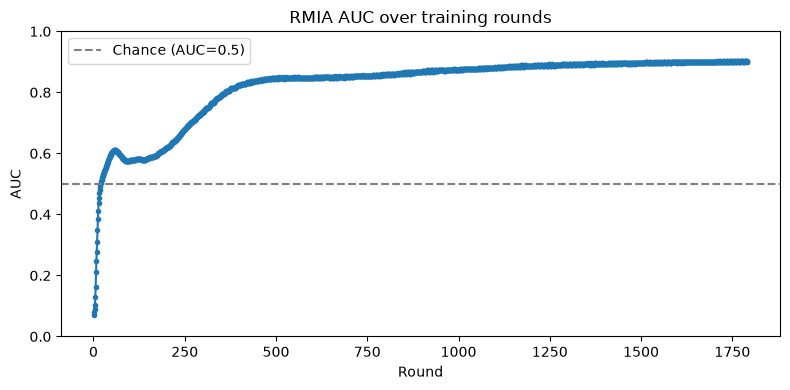

In [ ]:
with open(json_path) as f:
    data = json.load(f)

# sort by numeric round number, not lexicographic string order
rounds_and_auc = sorted(
    (int(re.search(r"(\d+)$", k).group(1)), v["auc"]) for k, v in data.items()
)
rounds, aucs = zip(*rounds_and_auc)

plt.figure(figsize=(8, 4))
plt.plot(rounds, aucs, marker=".")
plt.axhline(0.5, linestyle="--", color="gray", label="Chance (AUC=0.5)")
plt.xlabel("Round")
plt.ylabel("AUC")
plt.title("RMIA AUC over training rounds")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf
import os


class tinyCNNlite(tf.Module):
    def __init__(self):
        n_filters = 11
        window_len = 64
        sig_input = tf.keras.layers.Input(
            shape=(
                1,
                64,
            )
        )
        signal = tf.keras.layers.Conv1D(
            filters=n_filters, kernel_size=window_len, padding="same"
        )(sig_input)
        signal = tf.keras.layers.BatchNormalization()(signal)
        signal = tf.keras.layers.Activation("tanh")(signal)
        signal = tf.keras.layers.GlobalMaxPooling1D(
            data_format="channels_last"
        )(signal)

        rr_input = tf.keras.layers.Input(shape=(4,))
        rr = tf.keras.layers.Dense(32, activation="relu")(rr_input)
        rr = tf.keras.layers.Dense(16, activation="relu")(rr)
        rr = tf.keras.layers.Dense(8, activation="relu")(rr)

        combined = tf.keras.layers.Concatenate()([signal, rr])
        output = tf.keras.layers.Dense(3, activation="softmax")(combined)
        self.model = tf.keras.Model(
            inputs=[sig_input, rr_input], outputs=output
        )

        self.model.compile(
            optimizer="Adam",
            loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        )

    @tf.function(
        input_signature=[
            (
                tf.TensorSpec([None, 1, 64], dtype=tf.float32),
                tf.TensorSpec([None, 4], dtype=tf.float32),
            ),
            tf.TensorSpec(
                [
                    None,
                ],
                dtype=tf.int64,
            ),
        ],
    )
    def train(self, x, y):
        with tf.GradientTape() as tape:
            predictions = self.model(x)
            loss = self.model.loss(y, predictions)
        gradients = tape.gradient(loss, self.model.trainable_variables)
        self.model.optimizer.apply_gradients(
            zip(gradients, self.model.trainable_variables)
        )

        result = {"loss": loss}

        return result

    @tf.function(
        input_signature=[
            tf.TensorSpec([None, 1, 64], dtype=tf.float32, name="input_0"),
            tf.TensorSpec([None, 4], dtype=tf.float32, name="input_1"),
        ]
    )
    def infer(self, input_0, input_1):
        output = self.model([input_0, input_1])
        return {"output": output}

    @tf.function(input_signature=[tf.TensorSpec([], dtype=tf.string)])
    def save(self, checkpoint_path):
        tensor_names = [weight.name for weight in self.model.weights]
        tensors_to_save = [
            tf.convert_to_tensor(weight) for weight in self.model.weights
        ]
        tf.raw_ops.Save(
            filename=checkpoint_path,
            tensor_names=tensor_names,
            data=tensors_to_save,
            name="save",
        )

        return {"checkpoint_path": checkpoint_path}

    @tf.function(input_signature=[tf.TensorSpec([], dtype=tf.string)])
    def restore(self, checkpoint_path):
        restored_tensors = {}
        for var in self.model.weights:
            restored = tf.raw_ops.Restore(
                file_pattern=checkpoint_path,
                tensor_name=var.name,
                dt=var.dtype,
                name="restore",
            )
            print(restored)
            print(var)
            restored.set_shape(
                var.shape
            )  # <-- give Keras 3's shape_equal() something with known rank
            var.assign(restored)
            restored_tensors[var.name] = restored
        return restored_tensors

In [ ]:
from declearn.dataset.utils import load_data_array

FILEDIR = "/volatile/home/yb285618/SSF/declearn/examples/mitbih_tf"
data_folder = "data/mit-bih-aami"
data_folder = os.path.join(FILEDIR, data_folder, "client_0")
batch_size = 128

X_train = load_data_array(os.path.join(data_folder, "train_data.npy"))
RR_train = load_data_array(os.path.join(data_folder, "train_arr.npy"))
y_train = load_data_array(os.path.join(data_folder, "train_target.npy"))

train_ds = tf.data.Dataset.from_tensor_slices(((X_train, RR_train), y_train))
train_ds = train_ds.batch(batch_size=batch_size)

model = tinyCNNlite()

for x, y in train_ds:
    result = model.infer(*x)
    break

print(result["output"])

In [ ]:
SAVED_MODEL_DIR = "saved_model"

tf.saved_model.save(
    model,
    SAVED_MODEL_DIR,
    signatures={
        "train": model.train.get_concrete_function(),
        "infer": model.infer.get_concrete_function(),
        "save": model.save.get_concrete_function(),
        "restore": model.restore.get_concrete_function(),
    },
)

In [ ]:
converter = tf.lite.TFLiteConverter.from_saved_model(SAVED_MODEL_DIR)
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS,
    tf.lite.OpsSet.SELECT_TF_OPS,
]

converter.experimental_enable_resource_variables = True

tflite_model = converter.convert()
# interpreter = tf.lite.Interpreter(model_content=tflite_model)
# interpreter.allocate_tensors()
# interpreter.get_signature_list()

# infer = interpreter.get_signature_runner("infer")

# for x, y in train_ds:
#     result = infer(x=x)
#     print(result)
#     break

In [ ]:
from ai_edge_litert.interpreter import Interpreter


interpreter = Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()
print(interpreter.get_signature_list())

infer = interpreter.get_signature_runner("infer")
for x, y in train_ds:
    result = infer(input_0=x[0], input_1=x[1])
    print(type(result))  # nan here
    break

In [ ]:
result["output"]

In [ ]:
%load_ext autoreload
%autoreload 2

In [ ]:
import os
import sys
from declearn.dataset.utils import load_data_array
from model_tf import tinyCNN
from declearn.model.tensorflow import TensorflowModel
import tensorflow.keras as tf_keras

# os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"  # see issue #152
# os.environ["CUDA_VISIBLE_DEVICES"] = ""


FILEDIR = "/volatile/home/yb285618/SSF/declearn/examples/mitbih_tf"
matched_filters = load_data_array(
    os.path.join(FILEDIR, "data", "mit-bih-aami", "matched_filters.npy")
)


network = tinyCNN(matched_filters)


# opt = tf_keras.optimizers.Adam(learning_rate=0.01)
# network.compile(
#     optimizer=opt, loss=tf_keras.losses.SparseCategoricalCrossentropy()
# )

model = TensorflowModel(
    network, loss=tf_keras.losses.SparseCategoricalCrossentropy()
)

In [ ]:
data_folder = os.path.join(FILEDIR, "data/mit-bih-aami/", "client_0")

X_train = load_data_array(os.path.join(data_folder, "train_data.npy"))
RR_train = load_data_array(os.path.join(data_folder, "train_arr.npy"))
y_train = load_data_array(os.path.join(data_folder, "train_target.npy"))

X_test = load_data_array(os.path.join(data_folder, "valid_data.npy"))
RR_test = load_data_array(os.path.join(data_folder, "valid_arr.npy"))
y_test = load_data_array(os.path.join(data_folder, "valid_target.npy"))


In [ ]:
import tensorflow as tf
import numpy as np

In [ ]:
def prepare_data(X, rr, y):
    n_classes = np.unique(y).size
    n_samples = y.shape[0]
    weights = n_samples / n_classes * np.bincount(y)

    deriv_x = np.diff(X, axis=-1, prepend=X[..., :1])
    dataset = tf.data.Dataset.from_tensor_slices(((deriv_x, rr), y))

    return dataset

In [ ]:
from declearn.dataset.tensorflow._tensorflow import TensorflowDataset

tf_dataset = prepare_data(X_train, RR_train, y_train)
tf_dl_ds = TensorflowDataset(tf_dataset)

In [ ]:
spec = tf_dataset.element_spec

inputs = tf.nest.flatten(spec[0])
data_type = inputs[0].dtype
data_shape = []
for input in inputs:
    data_shape.append(input.shape)
    break

data_shape

In [ ]:
from tensorflow import TensorShape

model._model.build(
    input_shape=[TensorShape([None, 1, 64]), TensorShape([None, 4])]
)


In [ ]:
iter = tf_dl_ds.generate_batches(batch_size=64)

for batch in iter:
    gradients = model.compute_batch_gradients(batch)


In [ ]:
iter = tf_dl_ds.generate_batches(batch_size=64)


for batch in iter:
    print(batch[0][0].shape)
    print(batch[1].shape)
    unpacked = model._unpack_batch(batch)
    print(unpacked[0].shape)
    print(unpacked[1].shape)

    gradients = model.compute_batch_gradients(batch)

In [ ]:
import keras

tf.saved_model.save(
    network,
    "saved_model",
    signatures={"train_step": network.train_step.get_concrete_function()},
)

# network.build(X_train.shape)
# network.save("saved_model.keras")
# network2 = keras.saving.load_model("saved_model.keras")
# converter = tf.lite.TFLiteConverter.from_keras_model(network)

# tflite_model = converter.convert()


# converter.target_spec.supported_ops = [
#     tf.lite.OpsSet.TFLITE_BUILTINS,  # enable LiteRT ops.
#     tf.lite.OpsSet.SELECT_TF_OPS,  # enable TensorFlow ops.
# ]
# converter.experimental_enable_resource_variables = True

In [ ]:
info = [[1, 64], [4]]
info_a = {("a", "b")}
print(tuple(info[1]))
unique_shapes = {tuple(shp) for shp in info_a}

print(unique_shapes)
# value in values ==> [[1,64],[4]]
# wth is DATA_INFO_FIELDS?
# {'classes': <class 'declearn.data_info._fields.ClassesField'>,
# 'data_type': <class 'declearn.data_info._fields.DataTypeField'>,
# 'features_shape': <class 'declearn.data_info._fields.FeaturesShapeField'>,
# 'n_samples': <class 'declearn.data_info._fields.NbSamplesField'>}

# spec.combine(*values), why isn't it working?

client_data_info = [
    {"features_shape": [[1, 64], [4]]},
    {"features_shape": [[1, 64], [4]]},
]

set.intersection(*[set(info) for info in client_data_info])